# 03 · Differential expression (DESeq2)
**Goal:** genes that differ between groups: aging (older vs 3 months) and each treatment vs its control. **Input:** the counts of one method (`METHOD` in the first code cell: kallisto, STAR or RSEM). **Output:** `results/de/<METHOD>/*.csv` (not in git). **Kernel:** R (`ir`) · **Time:** ~1 min.

**Method.** `tximport` sums kallisto / RSEM estimates to genes (STAR counts are used directly). DESeq2 fits a negative binomial model per gene and tests whether the log2 fold change differs from 0; padj < 0.05 = DEG. Genes with < 10 reads in at least as many samples as the smallest group are not tested.

**Design.** Aging and rejuvenation mice come from different experiments, so they are analysed **separately**, each treatment against its own control (`sex` is a covariate in the aging model):

| Analysis | Mice | Model | Comparison |
|---|---|---|---|
| Aging | 12 (3 / 18 / 21 months, 2 male + 2 female each) | `~ sex + group` | 18 vs 3, 21 vs 3 months |
| aDR | 9 females (AL 4, aDR 5) | `~ group` | aDR vs AL |
| YMP | 6 males (PBS 3, YMP 3) | `~ group` | YMP vs PBS |

Terms: [docs/glossary.md](../docs/glossary.md).

In [1]:
# samples: one row per run; counts: gene-level counts of the chosen method; genes: gene id -> symbol (from the kallisto transcript names)
source('../R/helpers.R')
samples <- load_samples()
x <- load_txi(rownames(samples)); genes <- x$genes
METHOD <- 'kallisto'   # 'kallisto', 'STAR' or 'RSEM': which counts this notebook analyses (the choice is made in notebook 04, section 5)
txi <- switch(METHOD, kallisto = x$txi, STAR = load_star_counts()[, rownames(samples)], RSEM = load_rsem(rownames(samples)))
dir.create(file.path(ROOT, 'results/de', METHOD), recursive = TRUE, showWarnings = FALSE)
cat(METHOD, ':', if (is.matrix(txi)) nrow(txi) else nrow(txi$counts), 'genes x', nrow(samples), 'samples\n')
dplyr::count(samples, cohort, group, sex)

kallisto : 78348 genes x 27 samples


cohort,group,sex,n
<chr>,<fct>,<fct>,<int>
aging,aging 3mo,female,2
aging,aging 3mo,male,2
aging,aging 18mo,female,2
aging,aging 18mo,male,2
aging,aging 21mo,female,2
aging,aging 21mo,male,2
rejuvenation,AL,female,4
rejuvenation,aDR,female,5
rejuvenation,PBS,male,3


## 1 · All 27 samples: the cohort effect
In the PCA, PC1 should separate the two cohorts, which is why they are not pooled.

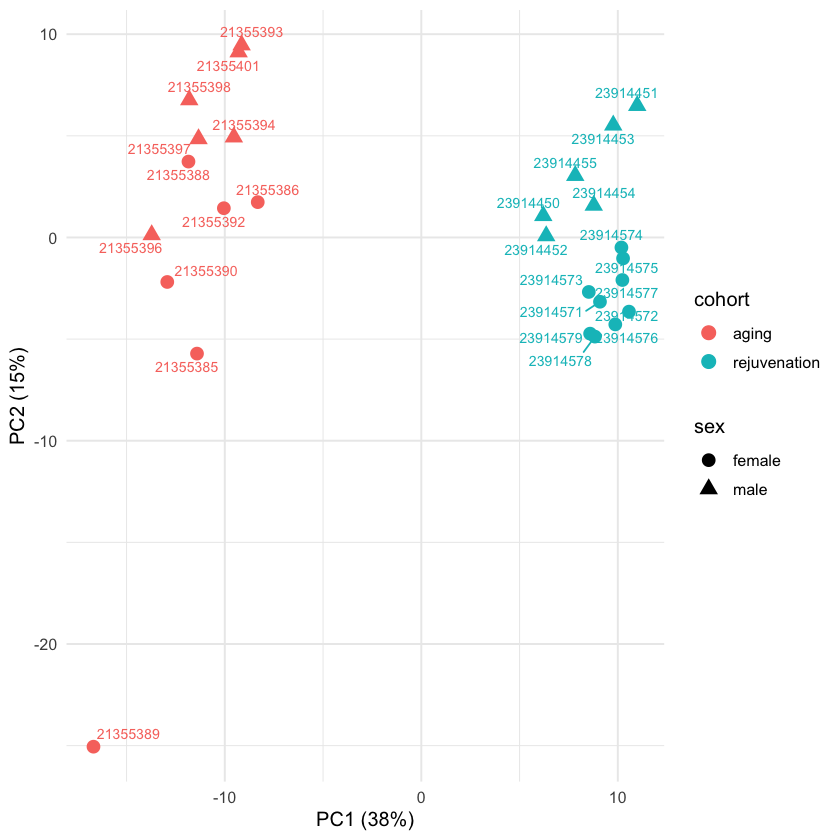

In [2]:
# vst = variance-stabilising transformation of counts, for plotting only
dds_all <- make_dds(txi, samples, ~ 1, min_n = 4)
pca_plot(dds_all, 'cohort', 'sex')

## 2 · Aging cohort (3, 18, 21 months)
### 2a · Outlier check
With all 12 mice, one 21-month female (SRR21355389) sits far from everyone on PC1.

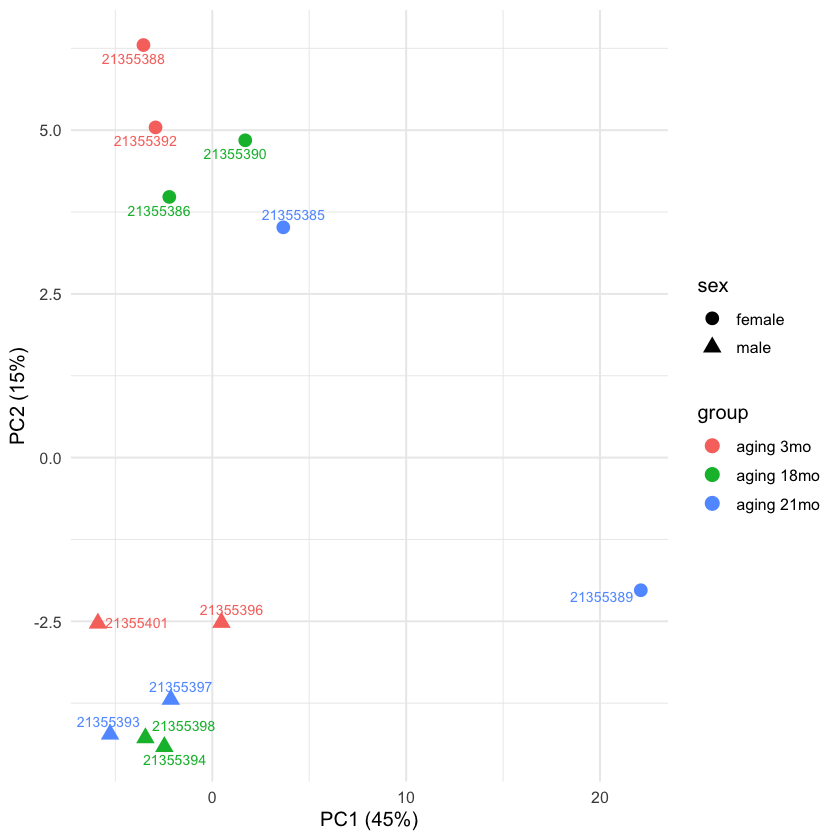

In [3]:
# aging mice only, all 12; PCA coloured by age group
s_age_all <- samples %>% filter(cohort == 'aging') %>% mutate(group = droplevels(group))
dds_age_all <- make_dds(txi, s_age_all, ~ sex + group, min_n = 4)
pca_plot(dds_age_all, 'group', 'sex')

In [4]:
# genes that most distinguish SRR21355389 from the other mice (vst difference)
outlier_genes(dds_age_all, 'SRR21355389', genes)

symbol,vst_diff
<chr>,<dbl>
Hba-a1,5.322108
Hbb-bs,5.284182
S100a8,5.240563
Hba-a2,4.885946
Hbb-bt,4.846806
S100a9,4.700186
Ngp,4.644707
Igkc,4.301508
Col1a1,4.204602


Its top genes are **haemoglobins** (Hbb, Hba: blood), **neutrophil** genes (S100a8/9, Ngp, Camp), **collagens** (Col1a1/2: meninges, vessels) and Igkc (antibody): contamination with blood and meningeal tissue (e.g. incomplete perfusion), not aging biology.

**Decision:** exclude it from the aging analysis. Change `EXCLUDE` below to keep it; 2b shows what the choice changes.

In [5]:
# the decision; set EXCLUDE <- character(0) to keep all 12 mice.
EXCLUDE <- 'SRR21355389'   # set to character(0) to keep all 12 aging samples
s_age <- s_age_all[!rownames(s_age_all) %in% EXCLUDE, ]
dds_age <- make_dds(txi, s_age, ~ sex + group, min_n = 3)

### 2b · DE results and sensitivity to the exclusion
`DEG` counts split into up (higher in the older group) and down.

In [6]:
# DE tables for 18 vs 3 and 21 vs 3 months; counts of up / down DEGs
age <- list(`18v3` = de_table(dds_age, c('group', 'aging 18mo', 'aging 3mo'), genes),
            `21v3` = de_table(dds_age, c('group', 'aging 21mo', 'aging 3mo'), genes))
bind_rows(lapply(age, n_deg), .id = 'contrast')

contrast,up,down
<chr>,<int>,<int>
18v3,101,25
21v3,82,52


In [7]:
# a = outlier excluded (used), b = all 12 mice: DEG counts, overlap, log2FC agreement (lfc_spearman)
# a = outlier excluded (used), b = all 12 samples
age_all_21v3 <- de_table(dds_age_all, c('group', 'aging 21mo', 'aging 3mo'), genes)
compare_de(age[['21v3']], age_all_21v3)

DEG_a,DEG_b,DEG_both,lfc_spearman
<int>,<int>,<int>,<dbl>
132,279,121,0.9810913


## 3 · Rejuvenation: aDR vs AL (females) and YMP vs PBS (males)

In [8]:
# one DESeq2 model per treatment (each against its own control); counts of up / down DEGs
s_adr <- samples %>% filter(group %in% c('AL', 'aDR')) %>% mutate(group = droplevels(group))
s_ymp <- samples %>% filter(group %in% c('PBS', 'YMP')) %>% mutate(group = droplevels(group))
dds_adr <- make_dds(txi, s_adr, ~ group, min_n = 4)
dds_ymp <- make_dds(txi, s_ymp, ~ group, min_n = 3)
rej <- list(aDR = de_table(dds_adr, c('group', 'aDR', 'AL'), genes),
            YMP = de_table(dds_ymp, c('group', 'YMP', 'PBS'), genes))
bind_rows(lapply(rej, n_deg), .id = 'contrast')

contrast,up,down
<chr>,<int>,<int>
aDR,64,75
YMP,17,24


## 4 · Save
One CSV per comparison with all tested genes (DESeq2 columns + gene symbol), read by later notebooks.

In [9]:
# writes results/de/<METHOD>/<comparison>.csv
res <- c(setNames(age, paste0('aging_', names(age))), rej)
invisible(imap(res, \(r, n) write_csv(r, file.path(ROOT, 'results/de', METHOD, paste0(n, '.csv')))))
list.files(file.path(ROOT, 'results/de', METHOD))

[1] "aDR.csv"        "aging_18v3.csv" "aging_21v3.csv" "YMP.csv"